# MMAD Practice_1: Метод ближайших соседей (KNN)
**Выполнил:** Ямщиков Владимир Сергеевич  
**Группа:** 26162  
**Факультет:** Механико-математический    
**Направление:** Математика и Компьютерные Науки  
**Дата:** 21.10.2026

## Установка необходимых библиотек
### Ниже представлен код установки библиотек.

In [33]:
# ! pip install scikit-learn matplotlib tabulate scipy

## Импорт библиотек

In [34]:
from typing import Tuple, List, Dict, Any, Optional
import warnings
import numpy as np
import matplotlib.pyplot as plt
from sklearn.neighbors import KNeighborsClassifier
from sklearn.model_selection import train_test_split, GridSearchCV, cross_val_score, StratifiedKFold
from sklearn.metrics import accuracy_score, classification_report
from sklearn.ensemble import RandomForestClassifier
from tabulate import tabulate
from scipy.stats import multivariate_normal

warnings.filterwarnings('ignore')
plt.style.use('seaborn-v0_8-whitegrid')

RANDOM_STATE: int = 42
np.random.seed(RANDOM_STATE)

print("✅ Окружение настроено")

✅ Окружение настроено


## 1. Генерация синтетических данных
 
Создадим два набора данных:
- **Простой**: два хорошо разделимых кластера
- **Сложный**: перекрывающиеся кластеры с выбросам

### Создание простого набора

In [ ]:
def generate_simple_dataset(
    n_samples: int = 200,
    random_state: int = RANDOM_STATE
) -> Tuple[np.ndarray, np.ndarray]:
    """
    Генерирует простой датасет с двумя хорошо разделимыми кластерами.
    
    Args:
        n_samples: количество объектов в каждом классе
        random_state: seed для воспроизводимости
    
    Returns:
        X: матрица признаков (2n_samples, 2)
        y: вектор меток (2n_samples,)
    """
    rng: np.random.RandomState = np.random.RandomState(random_state)
    
    # Класс 0: нормальное распределение с центром в (0, 0)
    class_0: np.ndarray = rng.normal(loc=0, scale=1, size=(n_samples, 2))
    # Класс 1: нормальное распределение с центром в (3, 3)
    class_1: np.ndarray = rng.normal(loc=3, scale=1.5, size=(n_samples, 2))
    
    X: np.ndarray = np.vstack([class_0, class_1])
    y: np.ndarray = np.hstack([np.zeros(n_samples), np.ones(n_samples)])
    
    return X, y

### Создание сложного набора

In [ ]:
def generate_complex_dataset(
    n_samples: int = 100,
    random_state: int = RANDOM_STATE
) -> Tuple[np.ndarray, np.ndarray]:
    """
    Генерирует сложный датасет с перекрывающимися кластерами и выбросами.
    
    Args:
        n_samples: базовое количество объектов
        random_state: seed для воспроизводимости
    
    Returns:
        X: матрица признаков
        y: вектор меток
    """
    rng: np.random.RandomState = np.random.RandomState(random_state)
    
    a: np.ndarray = rng.normal(loc=-2, scale=1, size=(n_samples * 4, 1))
    b: np.ndarray = rng.normal(loc=2, scale=1, size=(n_samples * 4, 1))
    c: np.ndarray = 5 * rng.randn(100, 2)
    
    # Создаём перекрывающиеся кластеры
    X: np.ndarray = np.vstack([
        np.hstack([a[:n_samples], a[n_samples:2*n_samples]]),
        np.hstack([b[:n_samples], b[n_samples:2*n_samples]]),
        c,
        np.hstack([a[2*n_samples:3*n_samples], b[2*n_samples:3*n_samples]]),
        np.hstack([b[3*n_samples:], a[3*n_samples:]])
    ])
    
    y: np.ndarray = np.hstack([
        np.zeros(2*n_samples + 50),
        np.ones(2*n_samples + 50)
    ])
    
    return X, y

### Генерация данных

In [ ]:
X_simple, y_simple = generate_simple_dataset(n_samples=200)
X_complex, y_complex = generate_complex_dataset(n_samples=100)

print(f"Простой датасет: X.shape = {X_simple.shape}, y.shape = {y_simple.shape}")
print(f"Сложный датасет: X.shape = {X_complex.shape}, y.shape = {y_complex.shape}")

Простой датасет: X.shape = (400, 2), y.shape = (400,)
Сложный датасет: X.shape = (500, 2), y.shape = (500,)


## 2. Визуализация данных

In [38]:
def plot_dataset(
    X: np.ndarray,
    y: np.ndarray,
    title: str,
    ax: Optional[plt.Axes] = None
) -> plt.Axes:
    """
    Визуализирует двумерный датасет с двумя классами.
    
    Args:
        X: матрица признаков
        y: вектор меток
        title: заголовок графика
        ax: оси matplotlib (опционально)
    
    Returns:
        ax: оси matplotlib
    """
    if ax is None:
        fig, ax = plt.subplots(figsize=(10, 8))
    
    colors: List[str] = ['red', 'blue']
    class_labels: List[str] = ['Class 0', 'Class 1']
    
    for class_idx in range(2):
        mask: np.ndarray = (y == class_idx)
        ax.scatter(
            X[mask, 0],
            X[mask, 1],
            c=colors[class_idx],
            s=50,
            alpha=0.6,
            edgecolors='black',
            linewidth=0.5,
            label=class_labels[class_idx]
        )
    
    ax.set_xlabel('Feature 1', fontsize=12)
    ax.set_ylabel('Feature 2', fontsize=12)
    ax.set_title(title, fontsize=14, fontweight='bold')
    ax.legend(loc='upper right', fontsize=10)
    ax.grid(True, alpha=0.3)
    
    return ax

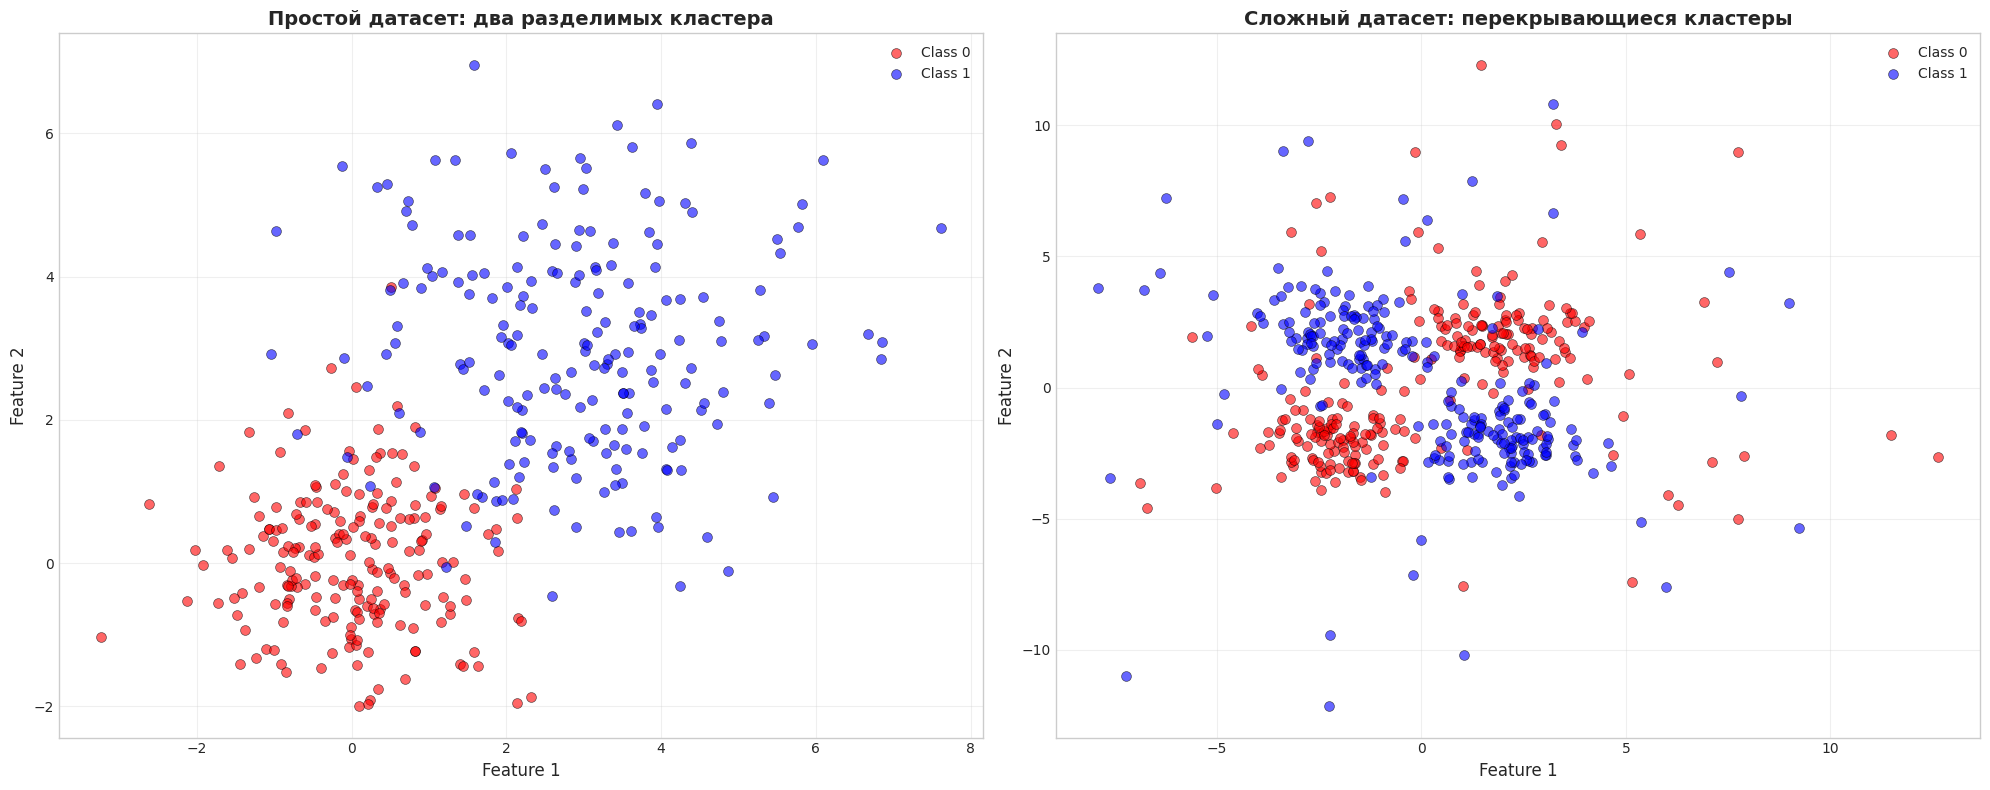

In [39]:
fig, axes = plt.subplots(1, 2, figsize=(20, 8))
plot_dataset(X_simple, y_simple, 'Простой датасет: два разделимых кластера', axes[0])
plot_dataset(X_complex, y_complex, 'Сложный датасет: перекрывающиеся кластеры', axes[1])
plt.tight_layout()
plt.show()

## 3. Визуализация границы решений KNN

In [40]:
def get_decision_boundary_grid(
    data: np.ndarray,
    border: float = 1.0,
    step: float = 0.05
) -> Tuple[np.ndarray, np.ndarray]:
    """
    Создаёт сетку для визуализации границы решений.
    
    Args:
        data: матрица признаков для определения границ
        border: отступ от границ данных
        step: шаг сетки
    
    Returns:
        xx, yy: координатные матрицы
    """
    x_min: float = data[:, 0].min() - border
    x_max: float = data[:, 0].max() + border
    y_min: float = data[:, 1].min() - border
    y_max: float = data[:, 1].max() + border
    
    xx, yy = np.meshgrid(
        np.arange(x_min, x_max, step),
        np.arange(y_min, y_max, step)
    )
    
    return xx, yy

In [ ]:
def plot_decision_boundary(
    X: np.ndarray,
    y: np.ndarray,
    clf: KNeighborsClassifier,
    title: str,
    cmap_name: str = 'RdYlBu'
) -> None:
    """
    Визуализирует границу решений классификатора.
    
    Args:
        X: матрица признаков
        y: вектор меток
        clf: обученный классификатор
        title: заголовок графика
        cmap_name: название цветовой карты
    """
    xx, yy = get_decision_boundary_grid(X)
    
    # Предсказания на сетке
    Z: np.ndarray = clf.predict_proba(np.c_[xx.ravel(), yy.ravel()])[:, 1]
    Z = Z.reshape(xx.shape)
    
    fig, ax = plt.subplots(figsize=(12, 10))
    contour = ax.pcolormesh(xx, yy, Z, cmap=cmap_name, alpha=0.7, shading='auto')
    plt.colorbar(contour, ax=ax, label='Probability of Class 1')
    
    colors: List[str] = ['red', 'blue']
    for class_idx in range(2):
        mask: np.ndarray = (y == class_idx)
        ax.scatter(
            X[mask, 0],
            X[mask, 1],
            c=colors[class_idx],
            s=100,
            edgecolors='black',
            linewidth=1.5,
            alpha=0.8,
            label=f'Class {class_idx}'
        )
    
    ax.set_xlabel('Feature 1', fontsize=12)
    ax.set_ylabel('Feature 2', fontsize=12)
    ax.set_title(title, fontsize=14, fontweight='bold')
    ax.legend(loc='upper right', fontsize=10)
    ax.grid(True, alpha=0.3)
    
    plt.tight_layout()
    plt.show()

### 3.1. KNN на простом датасете

Модель KNN:
KNeighborsClassifier(n_neighbors=25)

Предсказания классов:
[0. 0. 0.]

Вероятности классов:
[[0.84 0.16]
 [1.   0.  ]
 [1.   0.  ]]


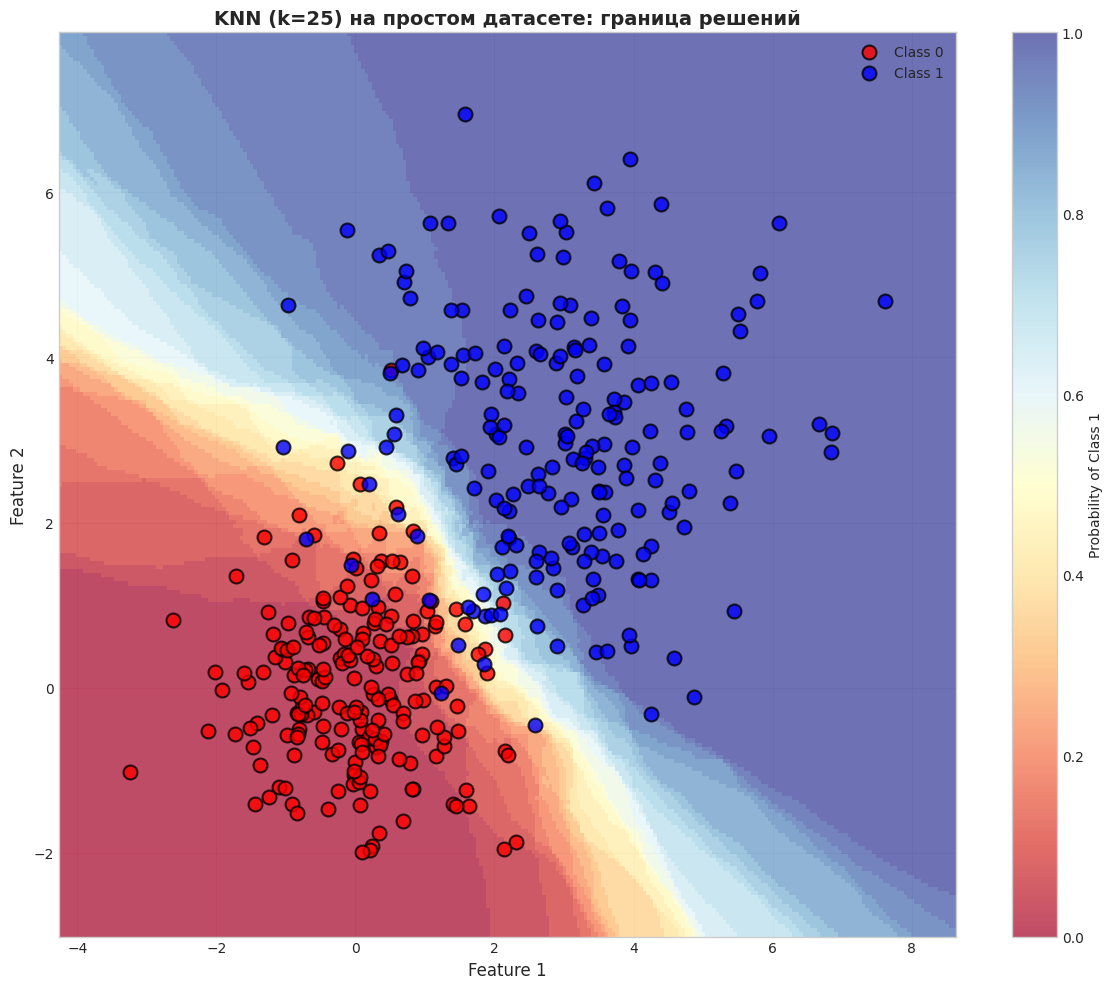

In [ ]:
knn_simple: KNeighborsClassifier = KNeighborsClassifier(n_neighbors=25)
knn_simple.fit(X_simple, y_simple)

print("Модель KNN:")
print(knn_simple)
print()

test_points: np.ndarray = np.array([
    [1, 1],
    [0.5, 0.5],
    [-10, -20]
])

print("Предсказания классов:")
print(knn_simple.predict(test_points))
print()

print("Вероятности классов:")
print(knn_simple.predict_proba(test_points))

# Визуализация границы решений
plot_decision_boundary(
    X_simple,
    y_simple,
    knn_simple,
    'KNN (k=25) на простом датасете: граница решений',
    cmap_name='RdYlBu'
)

### Вывод параметров KNN-Simple

In [55]:
knn_simple

,"n_neighbors n_neighbors: int, default=5Number of neighbors to use by default for :meth:`kneighbors` queries.",25
,"weights weights: {'uniform', 'distance'}, callable or None, default='uniform'Weight function used in prediction. Possible values:- 'uniform' : uniform weights. All points in each neighborhood are weighted equally.- 'distance' : weight points by the inverse of their distance. in this case, closer neighbors of a query point will have a greater influence than neighbors which are further away.- [callable] : a user-defined function which accepts an array of distances, and returns an array of the same shape containing the weights.Refer to the example entitled:ref:`sphx_glr_auto_examples_neighbors_plot_classification.py`showing the impact of the `weights` parameter on the decisionboundary.",'uniform'
,"algorithm algorithm: {'auto', 'ball_tree', 'kd_tree', 'brute'}, default='auto'Algorithm used to compute the nearest neighbors:- 'ball_tree' will use :class:`BallTree`- 'kd_tree' will use :class:`KDTree`- 'brute' will use a brute-force search.- 'auto' will attempt to decide the most appropriate algorithm based on the values passed to :meth:`fit` method.Note: fitting on sparse input will override the setting ofthis parameter, using brute force.",'auto'
,"leaf_size leaf_size: int, default=30Leaf size passed to BallTree or KDTree. This can affect thespeed of the construction and query, as well as the memoryrequired to store the tree. The optimal value depends on thenature of the problem.",30
,"p p: float, default=2Power parameter for the Minkowski metric. When p = 1, this is equivalentto using manhattan_distance (l1), and euclidean_distance (l2) for p = 2.For arbitrary p, minkowski_distance (l_p) is used. This parameter is expectedto be positive.",2
,"metric metric: str or callable, default='minkowski'Metric to use for distance computation. Default is ""minkowski"", whichresults in the standard Euclidean distance when p = 2. See thedocumentation of `scipy.spatial.distance`_ andthe metrics listed in:class:`~sklearn.metrics.pairwise.distance_metrics` for valid metricvalues.If metric is ""precomputed"", X is assumed to be a distance matrix andmust be square during fit. X may be a :term:`sparse graph`, in whichcase only ""nonzero"" elements may be considered neighbors.If metric is a callable function, it takes two arrays representing 1Dvectors as inputs and must return one value indicating the distancebetween those vectors. This works for Scipy's metrics, but is lessefficient than passing the metric name as a string.",'minkowski'
,"metric_params metric_params: dict, default=NoneAdditional keyword arguments for the metric function.",None
,"n_jobs n_jobs: int, default=NoneThe number of parallel jobs to run for neighbors search.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary `for more details.Doesn't affect :meth:`fit` method.",None


### 3.2. KNN на сложном датасете

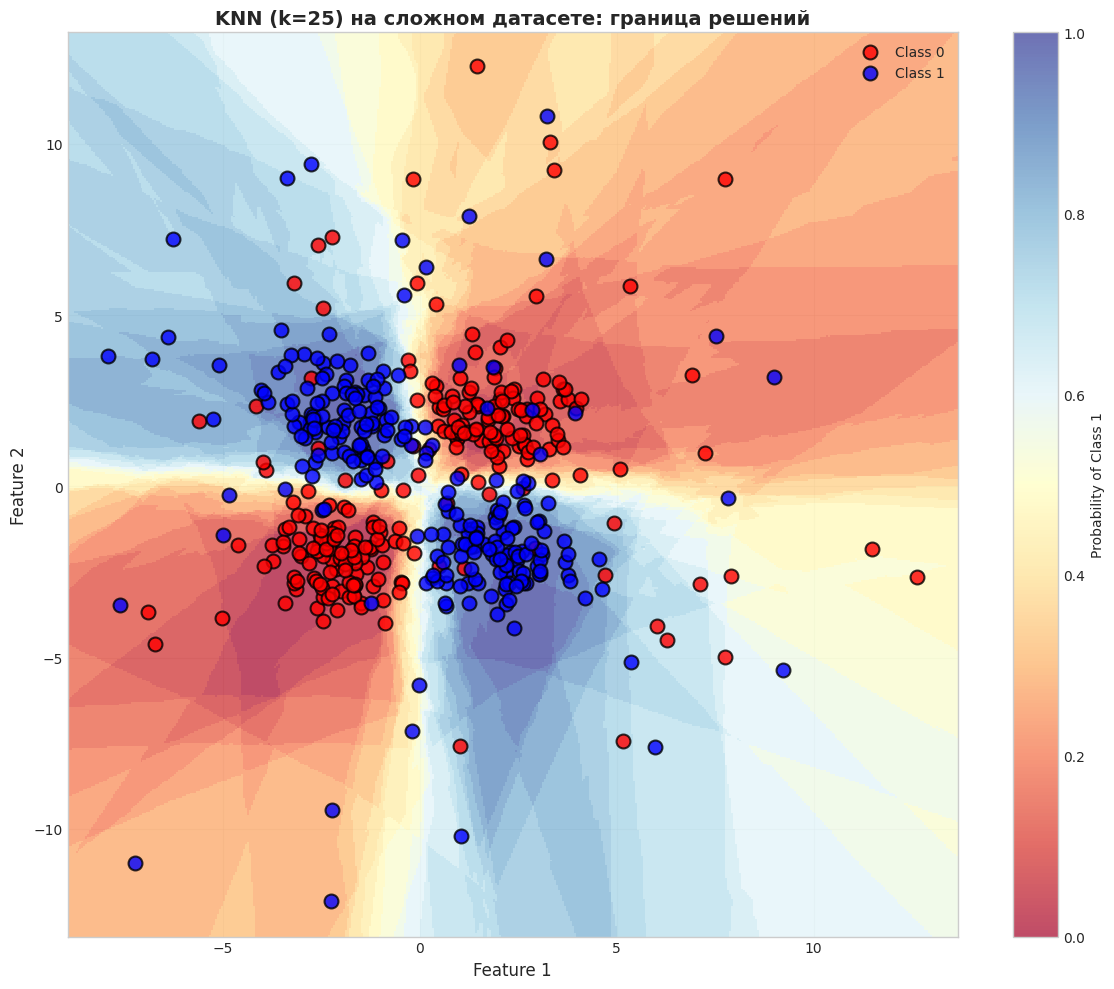

In [43]:
knn_complex: KNeighborsClassifier = KNeighborsClassifier(n_neighbors=25)
knn_complex.fit(X_complex, y_complex)
plot_decision_boundary(
    X_complex,
    y_complex,
    knn_complex,
    'KNN (k=25) на сложном датасете: граница решений',
    cmap_name='RdYlBu'
)

### Вывод параметров KNN-Complex

In [56]:
knn_complex

,"n_neighbors n_neighbors: int, default=5Number of neighbors to use by default for :meth:`kneighbors` queries.",25
,"weights weights: {'uniform', 'distance'}, callable or None, default='uniform'Weight function used in prediction. Possible values:- 'uniform' : uniform weights. All points in each neighborhood are weighted equally.- 'distance' : weight points by the inverse of their distance. in this case, closer neighbors of a query point will have a greater influence than neighbors which are further away.- [callable] : a user-defined function which accepts an array of distances, and returns an array of the same shape containing the weights.Refer to the example entitled:ref:`sphx_glr_auto_examples_neighbors_plot_classification.py`showing the impact of the `weights` parameter on the decisionboundary.",'uniform'
,"algorithm algorithm: {'auto', 'ball_tree', 'kd_tree', 'brute'}, default='auto'Algorithm used to compute the nearest neighbors:- 'ball_tree' will use :class:`BallTree`- 'kd_tree' will use :class:`KDTree`- 'brute' will use a brute-force search.- 'auto' will attempt to decide the most appropriate algorithm based on the values passed to :meth:`fit` method.Note: fitting on sparse input will override the setting ofthis parameter, using brute force.",'auto'
,"leaf_size leaf_size: int, default=30Leaf size passed to BallTree or KDTree. This can affect thespeed of the construction and query, as well as the memoryrequired to store the tree. The optimal value depends on thenature of the problem.",30
,"p p: float, default=2Power parameter for the Minkowski metric. When p = 1, this is equivalentto using manhattan_distance (l1), and euclidean_distance (l2) for p = 2.For arbitrary p, minkowski_distance (l_p) is used. This parameter is expectedto be positive.",2
,"metric metric: str or callable, default='minkowski'Metric to use for distance computation. Default is ""minkowski"", whichresults in the standard Euclidean distance when p = 2. See thedocumentation of `scipy.spatial.distance`_ andthe metrics listed in:class:`~sklearn.metrics.pairwise.distance_metrics` for valid metricvalues.If metric is ""precomputed"", X is assumed to be a distance matrix andmust be square during fit. X may be a :term:`sparse graph`, in whichcase only ""nonzero"" elements may be considered neighbors.If metric is a callable function, it takes two arrays representing 1Dvectors as inputs and must return one value indicating the distancebetween those vectors. This works for Scipy's metrics, but is lessefficient than passing the metric name as a string.",'minkowski'
,"metric_params metric_params: dict, default=NoneAdditional keyword arguments for the metric function.",None
,"n_jobs n_jobs: int, default=NoneThe number of parallel jobs to run for neighbors search.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary `for more details.Doesn't affect :meth:`fit` method.",None


## 4. Разделение на обучающую и тестовую выборки

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X_complex,
    y_complex,
    test_size=0.3,
    random_state=RANDOM_STATE,
    stratify=y_complex  # для сохранения баланса классов
)

print(f"Обучающая выборка: X_train.shape = {X_train.shape}, y_train.shape = {y_train.shape}")
print(f"Тестовая выборка: X_test.shape = {X_test.shape}, y_test.shape = {y_test.shape}")
print()
print(f"Распределение классов в train: {np.bincount(y_train.astype(int))}")
print(f"Распределение классов в test: {np.bincount(y_test.astype(int))}")


Обучающая выборка: X_train.shape = (350, 2), y_train.shape = (350,)
Тестовая выборка: X_test.shape = (150, 2), y_test.shape = (150,)

Распределение классов в train: [175 175]
Распределение классов в test: [75 75]


In [57]:
X_train

array([[  4.63238206,  -3.00252936],
       [  0.40557234,   2.92617755],
       [  0.48060388,  -2.31137644],
       [ -3.4123037 ,  -1.24806697],
       [ -1.9324718 ,  -0.59720569],
       [  3.22742091,  10.81627362],
       [ -2.64511975,  -2.75373616],
       [ -0.55872671,   3.24608519],
       [  5.07888081,   0.52141375],
       [ -3.86726519,   2.47146836],
       [  2.07736831,   2.47897983],
       [  0.5915387 ,  -1.38962973],
       [ -2.58936476,   0.91893667],
       [  2.75750771,   0.99191369],
       [ -2.44004449,  -0.65096981],
       [  2.177701  ,  -2.83972184],
       [  0.80212211,   1.57901552],
       [  3.2136138 ,   6.64576265],
       [  2.38406545,   2.83569211],
       [  0.61720027,   2.37730049],
       [ -0.9110494 ,   1.48878432],
       [ -1.08213805,   3.12656503],
       [  0.95549534,   0.23218274],
       [ -1.93571998,   1.01039518],
       [ -3.42474819,  -3.40185106],
       [ -2.31526924,   4.44575198],
       [  2.68605146,   2.04808495],
 

In [58]:
X_test

array([[  2.39913611,  -1.18649036],
       [  2.02609105,  -2.50694318],
       [  3.75534084,   2.54336019],
       [  3.64496771,   2.82940558],
       [  1.27286282,  -1.12767936],
       [  5.33337345,   5.84647795],
       [  1.85762051,   1.13600923],
       [ -3.91328024,   0.46324211],
       [  1.96501151,  -1.77590752],
       [ -1.93019792,   2.93567839],
       [ -2.05952536,   1.45314106],
       [ -3.19620662,  -2.82068232],
       [  3.02915564,  -1.02488027],
       [  2.12200981,  -0.46726109],
       [  1.29682357,  -2.40122047],
       [  0.93237957,   1.40760608],
       [ -0.08192941,  -1.45290262],
       [  2.0052437 ,   0.60143243],
       [ -1.88648265,   2.72167206],
       [ -0.44867847,   7.20058608],
       [  0.14372411,   6.39225931],
       [  1.22169527,  -1.37165449],
       [  3.69645637,  -2.20219265],
       [ -4.83488072,  -0.23855678],
       [ -2.58644225,   7.0467372 ],
       [  3.55115198,   2.50091719],
       [ -1.17745509,  -2.91942423],
 

In [59]:
y_train

array([1., 0., 0., 0., 0., 1., 0., 1., 0., 1., 0., 1., 1., 0., 1., 1., 0.,
       1., 0., 0., 1., 1., 1., 1., 0., 1., 0., 1., 0., 1., 0., 0., 1., 0.,
       0., 0., 1., 1., 1., 0., 1., 1., 0., 1., 1., 1., 0., 1., 1., 1., 1.,
       0., 0., 0., 0., 0., 0., 1., 1., 0., 0., 0., 0., 0., 1., 1., 0., 1.,
       1., 0., 1., 0., 1., 0., 0., 1., 0., 0., 1., 0., 0., 0., 0., 1., 1.,
       0., 1., 0., 0., 0., 0., 0., 0., 1., 1., 0., 1., 1., 0., 1., 1., 1.,
       1., 1., 0., 1., 0., 0., 0., 1., 1., 1., 0., 1., 0., 0., 1., 0., 1.,
       0., 0., 0., 0., 0., 0., 0., 1., 0., 1., 0., 1., 0., 1., 1., 0., 1.,
       0., 1., 1., 0., 1., 1., 0., 1., 0., 1., 0., 0., 1., 1., 1., 1., 0.,
       1., 1., 0., 1., 1., 1., 1., 0., 0., 0., 1., 1., 1., 0., 0., 0., 1.,
       1., 0., 1., 1., 0., 0., 0., 0., 1., 1., 1., 1., 1., 1., 0., 0., 1.,
       0., 0., 0., 0., 1., 1., 0., 0., 0., 1., 1., 0., 0., 1., 0., 0., 1.,
       1., 0., 1., 0., 1., 1., 1., 1., 0., 0., 1., 0., 1., 1., 0., 0., 1.,
       0., 0., 1., 0., 1.

In [60]:
y_test

array([1., 1., 0., 0., 1., 0., 0., 0., 1., 1., 1., 0., 1., 1., 1., 0., 1.,
       0., 1., 1., 1., 1., 1., 1., 0., 0., 0., 1., 1., 0., 0., 1., 0., 1.,
       0., 0., 1., 1., 1., 1., 1., 0., 1., 0., 0., 0., 1., 0., 1., 1., 0.,
       1., 0., 0., 0., 0., 0., 0., 0., 1., 0., 1., 1., 0., 1., 0., 0., 1.,
       1., 1., 1., 1., 1., 0., 0., 0., 0., 1., 1., 1., 0., 0., 0., 1., 1.,
       0., 1., 0., 0., 1., 1., 0., 0., 0., 0., 1., 1., 0., 0., 1., 0., 0.,
       0., 0., 0., 1., 0., 1., 1., 1., 0., 1., 1., 1., 0., 1., 0., 1., 1.,
       1., 1., 0., 1., 1., 0., 1., 0., 1., 1., 0., 0., 0., 1., 1., 0., 1.,
       0., 0., 0., 0., 1., 0., 0., 1., 0., 1., 0., 0., 1., 0.])

## 5. Влияние параметра k на качество классификации

### Базовый тест с k=1 и перебор вариантов

Accuracy с k=1: 0.8333



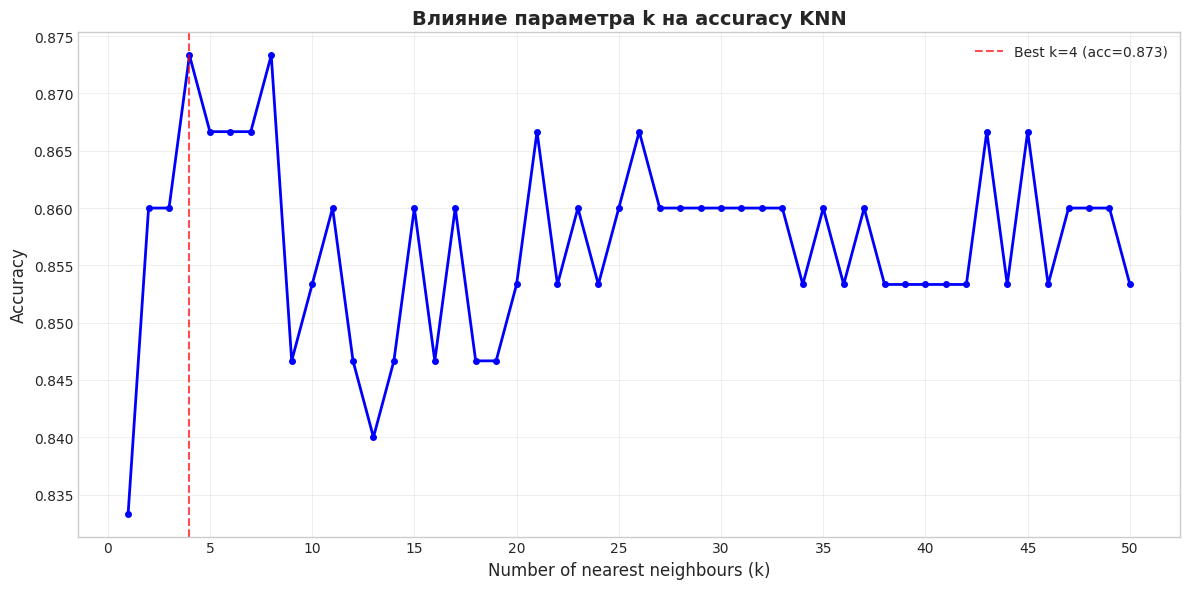

Лучшее k: 4 с accuracy = 0.8733


In [ ]:
knn_k1: KNeighborsClassifier = KNeighborsClassifier(n_neighbors=1)
knn_k1.fit(X_train, y_train)
accuracy_k1: float = accuracy_score(y_test, knn_k1.predict(X_test))
print(f"Accuracy с k=1: {accuracy_k1:.4f}")
print()

k_range: range = range(1, 51)
accuracies: List[float] = []

for k in k_range:
    knn: KNeighborsClassifier = KNeighborsClassifier(n_neighbors=k)
    knn.fit(X_train, y_train)
    acc: float = accuracy_score(y_test, knn.predict(X_test))
    accuracies.append(acc)

fig, ax = plt.subplots(figsize=(12, 6))
ax.plot(list(k_range), accuracies, 'b-', linewidth=2, marker='o', markersize=4)
ax.set_xlabel('Number of nearest neighbours (k)', fontsize=12)
ax.set_ylabel('Accuracy', fontsize=12)
ax.set_title('Влияние параметра k на accuracy KNN', fontsize=14, fontweight='bold')
ax.grid(True, alpha=0.3)
ax.set_xticks(range(0, 51, 5))

best_k: int = k_range[np.argmax(accuracies)]
best_acc: float = max(accuracies)
ax.axvline(x=best_k, color='red', linestyle='--', alpha=0.7, label=f'Best k={best_k} (acc={best_acc:.3f})')
ax.legend(loc='best', fontsize=10)

plt.tight_layout()
plt.show()

print(f"Лучшее k: {best_k} с accuracy = {best_acc:.4f}")

## 6. Подбор оптимального k с помощью GridSearchCV

In [ ]:
cv_strategy: StratifiedKFold = StratifiedKFold(
    n_splits=10,
    shuffle=True,
    random_state=RANDOM_STATE
)

param_grid: Dict[str, List[int]] = {
    'n_neighbors': list(range(1, 101))
}

knn_base: KNeighborsClassifier = KNeighborsClassifier()

grid_search: GridSearchCV = GridSearchCV(
    estimator=knn_base,
    param_grid=param_grid,
    cv=cv_strategy,
    scoring='accuracy',
    n_jobs=-1,
    return_train_score=True
)

grid_search.fit(X_complex, y_complex)

print("Лучшие параметры:", grid_search.best_params_)
print(f"Лучшая accuracy: {grid_search.best_score_:.4f}")
print()

cv_results: Dict[str, Any] = grid_search.cv_results_
means: np.ndarray = cv_results['mean_test_score']
stds: np.ndarray = cv_results['std_test_score']
params: np.ndarray = cv_results['params']

Лучшие параметры: {'n_neighbors': 6}
Лучшая accuracy: 0.8860



### 6.1. Визуализация результатов кросс-валидации

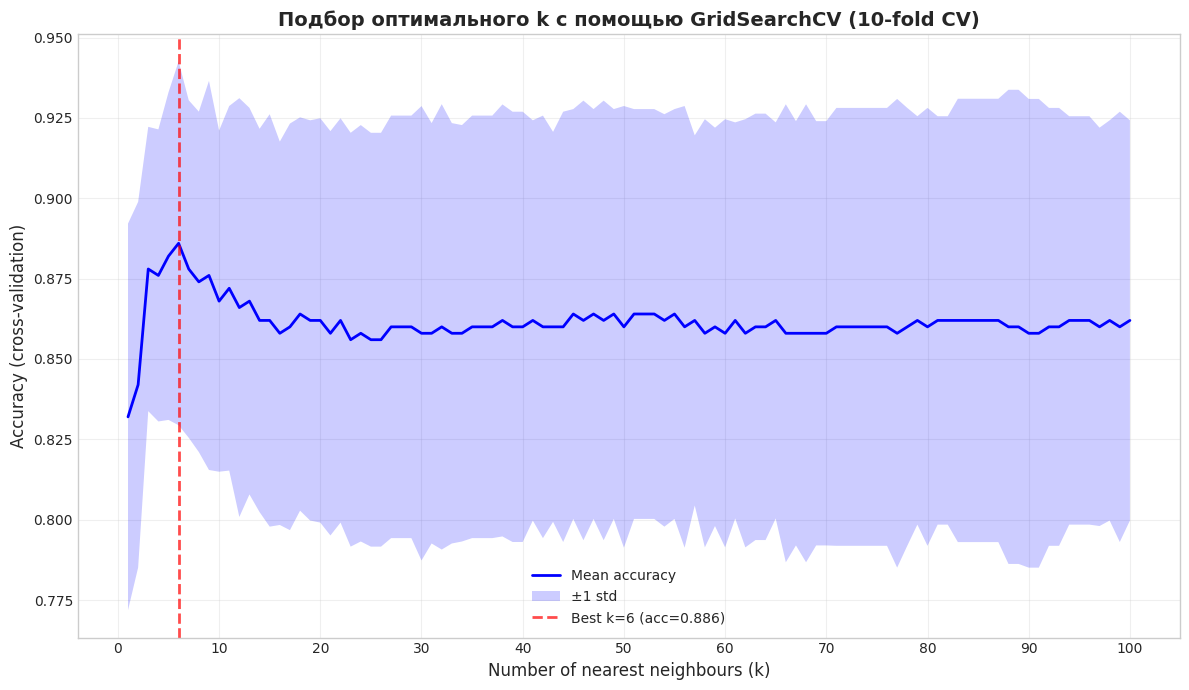

In [ ]:
fig, ax = plt.subplots(figsize=(12, 7))

ax.plot(range(1, 101), means, 'b-', linewidth=2, label='Mean accuracy')

# Область стандартного отклонения
ax.fill_between(
    range(1, 101),
    means + stds,
    means - stds,
    alpha=0.2,
    facecolor='blue',
    label='±1 std'
)

best_k_cv: int = grid_search.best_params_['n_neighbors']
ax.axvline(
    x=best_k_cv,
    color='red',
    linestyle='--',
    linewidth=2,
    alpha=0.7,
    label=f'Best k={best_k_cv} (acc={grid_search.best_score_:.3f})'
)

ax.set_xlabel('Number of nearest neighbours (k)', fontsize=12)
ax.set_ylabel('Accuracy (cross-validation)', fontsize=12)
ax.set_title('Подбор оптимального k с помощью GridSearchCV (10-fold CV)', fontsize=14, fontweight='bold')
ax.legend(loc='best', fontsize=10)
ax.grid(True, alpha=0.3)
ax.set_xticks(range(0, 101, 10))

plt.tight_layout()
plt.show()

### 6.2. Сравнение: test accuracy vs cross-validation accuracy

In [ ]:
print("=" * 70)
print("СРАВНЕНИЕ: Test Accuracy vs Cross-Validation Accuracy")
print("=" * 70)
accuracy_table_data: List[List[str]] = []

for k in [1, 5, 10, 15, 20, 25, best_k_cv, 50, 75, 100]:
    idx: int = k - 1
    if idx < len(means):
        knn_temp: KNeighborsClassifier = KNeighborsClassifier(n_neighbors=k)
        knn_temp.fit(X_train, y_train)
        test_acc: float = accuracy_score(y_test, knn_temp.predict(X_test))
    
    accuracy_table_data.append([
        f"{k:<5}",
        f"{test_acc:<15.4f}",
        f"{means[idx]:<18.4f}",
        f"{stds[idx]:<10.4f}"
    ])

print(tabulate(
    accuracy_table_data,
    headers=["k", "Test Accuracy", "CV Mean Accuracy", "CV Std"],
    tablefmt="pretty",
    stralign="center"
))

СРАВНЕНИЕ: Test Accuracy vs Cross-Validation Accuracy
+-----+---------------+------------------+--------+
|  k  | Test Accuracy | CV Mean Accuracy | CV Std |
+-----+---------------+------------------+--------+
|  1  |    0.8333     |      0.8320      | 0.0601 |
|  5  |    0.8667     |      0.8820      | 0.0510 |
| 10  |    0.8533     |      0.8680      | 0.0531 |
| 15  |    0.8600     |      0.8620      | 0.0642 |
| 20  |    0.8533     |      0.8620      | 0.0629 |
| 25  |    0.8600     |      0.8560      | 0.0644 |
|  6  |    0.8667     |      0.8860      | 0.0566 |
| 50  |    0.8533     |      0.8600      | 0.0687 |
| 75  |    0.8667     |      0.8600      | 0.0681 |
| 100 |    0.8667     |      0.8620      | 0.0623 |
+-----+---------------+------------------+--------+


## 7. Финальная модель и классификационный отчёт

### Обучение финальной модели с оптимальным k

Классификационный отчёт для финальной модели KNN:
              precision    recall  f1-score   support

     Class 0       0.86      0.88      0.87        75
     Class 1       0.88      0.85      0.86        75

    accuracy                           0.87       150
   macro avg       0.87      0.87      0.87       150
weighted avg       0.87      0.87      0.87       150



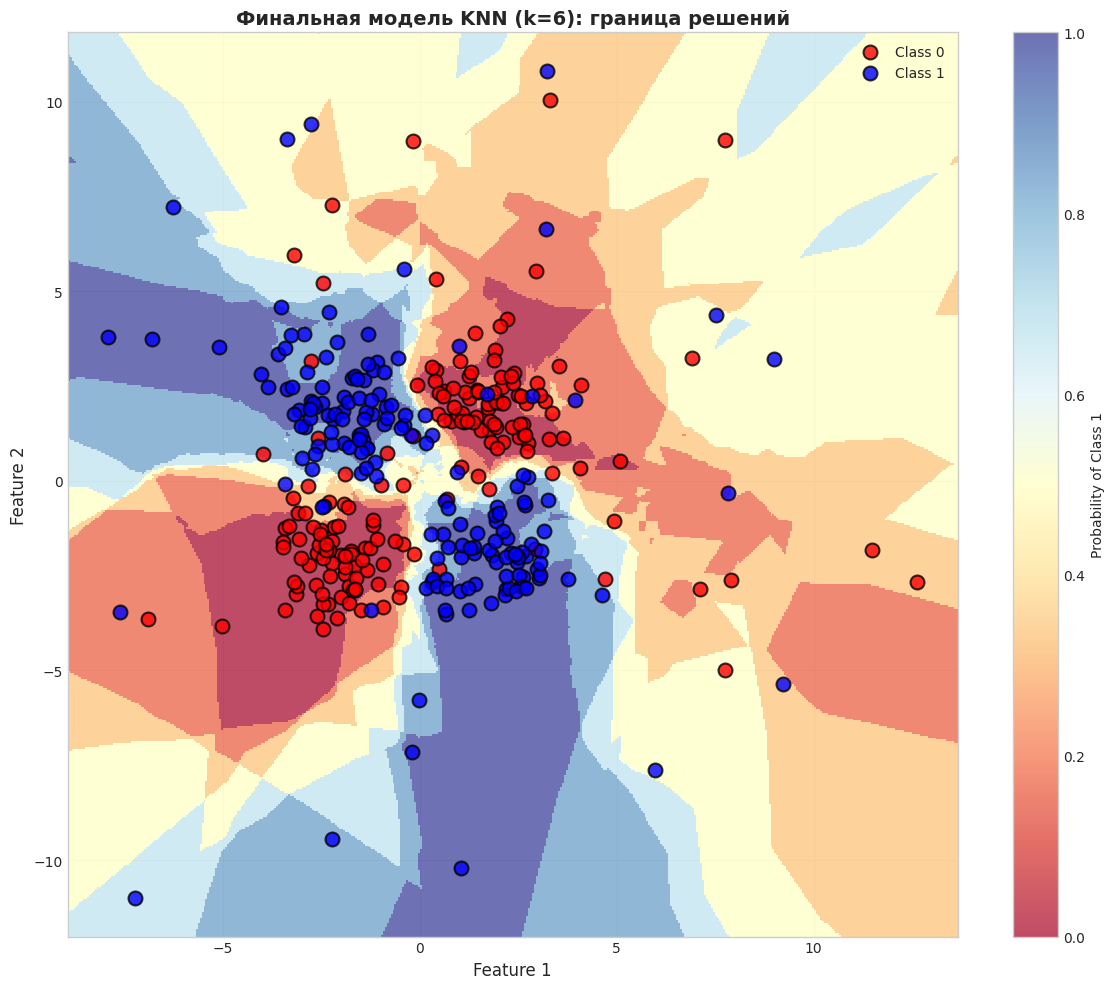

In [ ]:
knn_final: KNeighborsClassifier = KNeighborsClassifier(n_neighbors=best_k_cv)
knn_final.fit(X_train, y_train)

# Предсказания на тестовой выборке
y_pred: np.ndarray = knn_final.predict(X_test)
y_pred_proba: np.ndarray = knn_final.predict_proba(X_test)

print("Классификационный отчёт для финальной модели KNN:")
print("=" * 70)
print(classification_report(y_test, y_pred, target_names=['Class 0', 'Class 1']))
print("=" * 70)

plot_decision_boundary(
    X_train,
    y_train,
    knn_final,
    f'Финальная модель KNN (k={best_k_cv}): граница решений',
    cmap_name='RdYlBu'
)

## 8. Влияние метрики расстояния

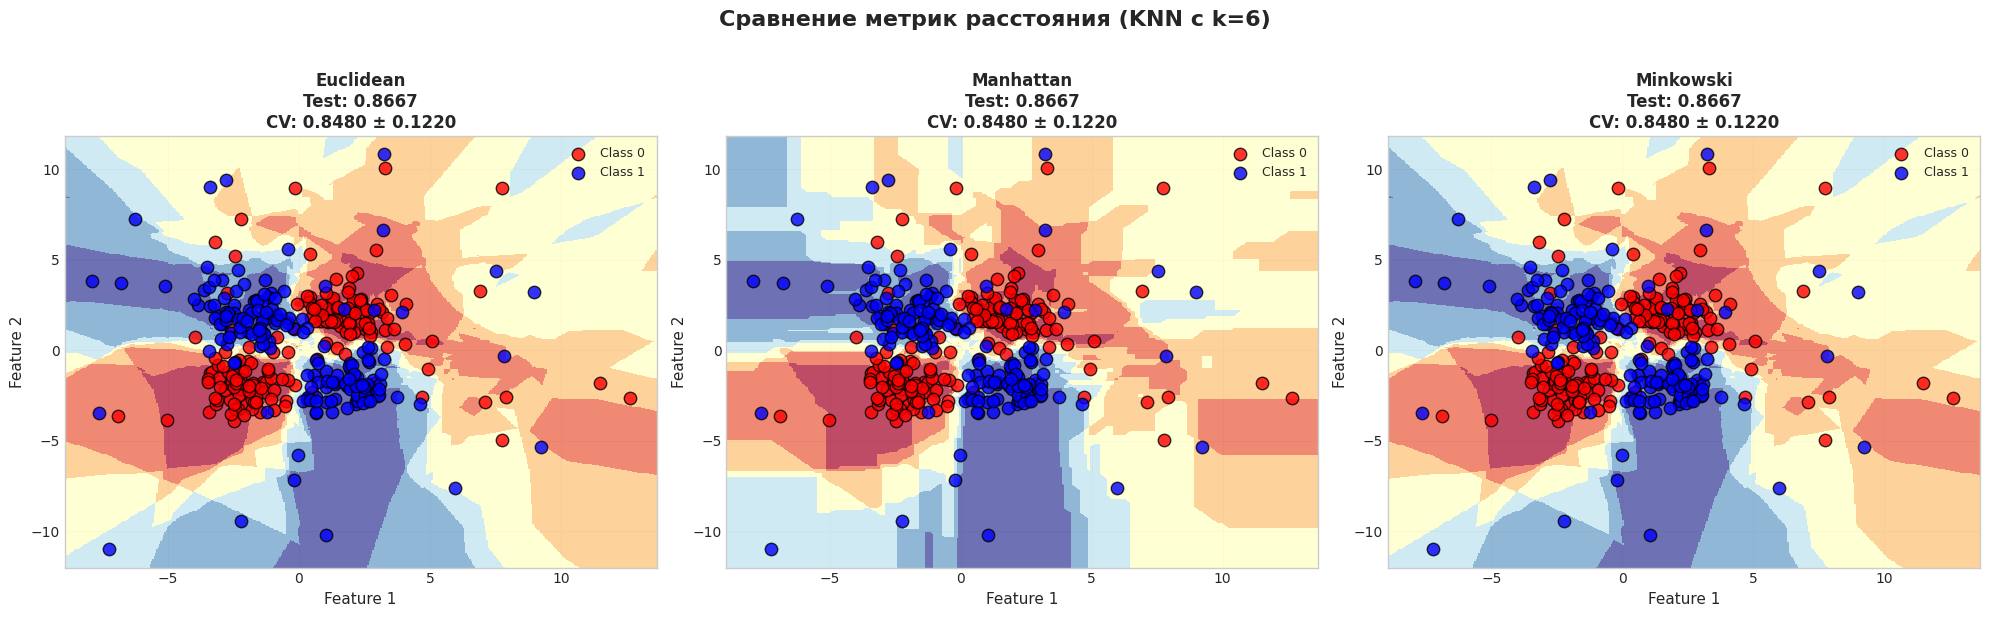

In [ ]:
metrics: List[str] = ['euclidean', 'manhattan', 'minkowski']
metric_results: Dict[str, Dict[str, float]] = {}

fig, axes = plt.subplots(1, 3, figsize=(20, 6))

for idx, metric in enumerate(metrics):
    knn_metric: KNeighborsClassifier = KNeighborsClassifier(
        n_neighbors=best_k_cv,
        metric=metric
    )
    
    knn_metric.fit(X_train, y_train)
    
    test_acc: float = accuracy_score(y_test, knn_metric.predict(X_test))
    
    # Cross-validation accuracy
    cv_scores: np.ndarray = cross_val_score(
        knn_metric,
        X_complex,
        y_complex,
        cv=10,
        scoring='accuracy',
        n_jobs=-1
    )
    cv_mean: float = cv_scores.mean()
    cv_std: float = cv_scores.std()
    
    metric_results[metric] = {
        'test_accuracy': test_acc,
        'cv_mean': cv_mean,
        'cv_std': cv_std
    }
    
    # plot_decision_boundary(
    #     X_train,
    #     y_train,
    #     knn_metric,
    #     f'KNN (k={best_k_cv}, metric={metric})\nTest Accuracy: {acc:.4f}',
    #     cmap_name='RdYlBu'
    # )

    xx, yy = get_decision_boundary_grid(X_train)
    Z: np.ndarray = knn_metric.predict_proba(np.c_[xx.ravel(), yy.ravel()])[:, 1]
    Z = Z.reshape(xx.shape)
    
    ax = axes[idx]
    contour = ax.pcolormesh(xx, yy, Z, cmap='RdYlBu', alpha=0.7, shading='auto')
    
    colors: List[str] = ['red', 'blue']
    for class_idx in range(2):
        mask: np.ndarray = (y_train == class_idx)
        ax.scatter(
            X_train[mask, 0],
            X_train[mask, 1],
            c=colors[class_idx],
            s=80,
            edgecolors='black',
            linewidth=1,
            alpha=0.8,
            label=f'Class {class_idx}'
        )
    
    ax.set_xlabel('Feature 1', fontsize=11)
    ax.set_ylabel('Feature 2', fontsize=11)
    ax.set_title(
        f'{metric.capitalize()}\n'
        f'Test: {test_acc:.4f}\n'
        f'CV: {cv_mean:.4f} ± {cv_std:.4f}',
        fontsize=12,
        fontweight='bold'
    )
    ax.legend(loc='upper right', fontsize=9)
    ax.grid(True, alpha=0.3)

plt.suptitle(f'Сравнение метрик расстояния (KNN с k={best_k_cv})', fontsize=16, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

### Сравнение метрик расстояния

In [61]:
metrics_difference_table_data: List[List[str]] = []

for metric, results in metric_results.items():
    cv_range = f"{results['cv_mean'] - results['cv_std']:.4f} - {results['cv_mean'] + results['cv_std']:.4f}"

    metrics_difference_table_data.append([
        f"{metric:<15}",
        f"{results['test_accuracy']:<15.4f}",
        f"{results['cv_mean']:<12.4f}",
        f"{results['cv_std']:<10.4f}",
        f"{cv_range}"
    ])

print(tabulate(
    metrics_difference_table_data,
    headers=["Метрика", "Test Accuracy", "CV Mean", "CV Std", "CV Range"],
    tablefmt="pretty",
    stralign="center"
))

best_metric: str = max(metric_results, key=lambda x: metric_results[x]['cv_mean'])
print(f"\nЛучшая метрика: {best_metric.upper()}")
print(f"   CV Accuracy: {metric_results[best_metric]['cv_mean']:.4f} ± {metric_results[best_metric]['cv_std']:.4f}")
print(f"   Test Accuracy: {metric_results[best_metric]['test_accuracy']:.4f}")

+-----------+---------------+---------+--------+-----------------+
|  Метрика  | Test Accuracy | CV Mean | CV Std |    CV Range     |
+-----------+---------------+---------+--------+-----------------+
| euclidean |    0.8667     | 0.8480  | 0.1220 | 0.7260 - 0.9700 |
| manhattan |    0.8667     | 0.8480  | 0.1220 | 0.7260 - 0.9700 |
| minkowski |    0.8667     | 0.8480  | 0.1220 | 0.7260 - 0.9700 |
+-----------+---------------+---------+--------+-----------------+

Лучшая метрика: EUCLIDEAN
   CV Accuracy: 0.8480 ± 0.1220
   Test Accuracy: 0.8667


## 10. Оценка Бейесовской ошибки (Bayes Error Rate)

### **Бейесовская ошибка** - это минимально возможная ошибка классификации, обусловленная исключительно перекрытием истинных распределений классов.

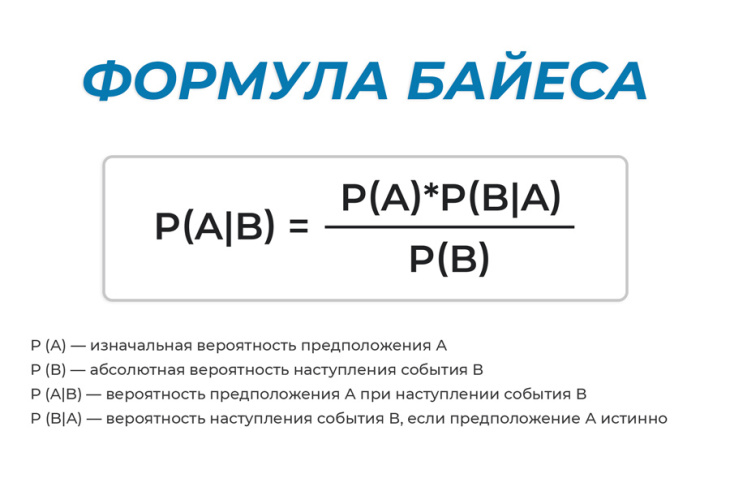

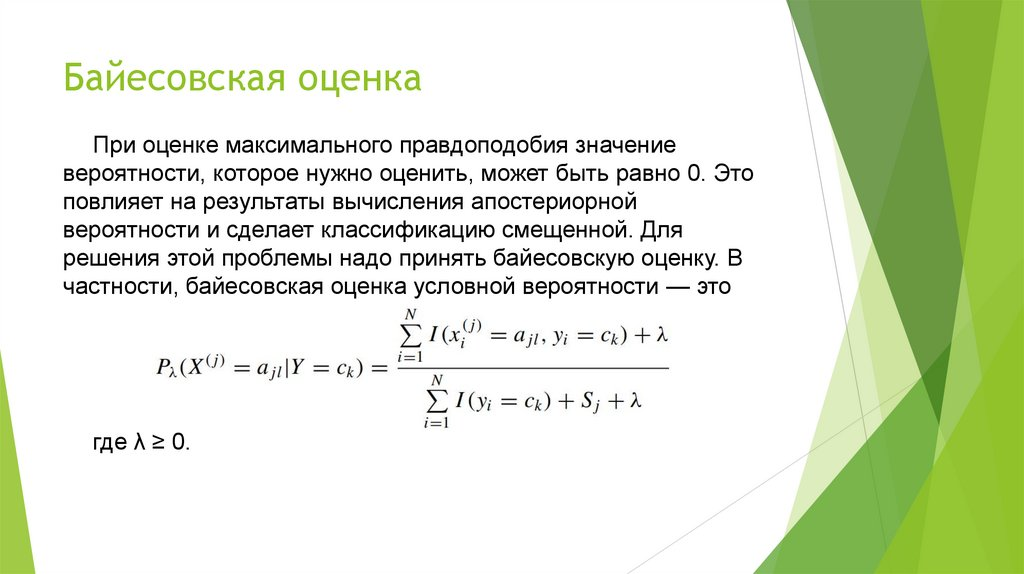

In [ ]:
def calculate_bayes_error_simple(
    n_samples: int = 1_000_000,
    random_state: int = RANDOM_STATE
) -> float:
    """
    Точный расчёт Бейесовской ошибки для простого датасета 
    методом Монте-Карло с использованием истинных PDF.
    """
    rng: np.random.RandomState = np.random.RandomState(random_state)
    
    # Истинные параметры генерации (математические ожидания и ковариационные матрицы)
    mu_0, cov_0 = [0, 0], np.eye(2)
    mu_1, cov_1 = [3, 3], (1.5**2) * np.eye(2)
    prior_0, prior_1 = 0.5, 0.5
    
    n_class_0: int = int(n_samples * prior_0)
    n_class_1: int = n_samples - n_class_0
    
    X_0: np.ndarray = rng.multivariate_normal(mu_0, cov_0, n_class_0)
    X_1: np.ndarray = rng.multivariate_normal(mu_1, cov_1, n_class_1)

    print(f"X0: {X_0}")
    print(f"X1: {X_1}")
    
    X_large: np.ndarray = np.vstack([X_0, X_1])
    y_true: np.ndarray = np.hstack([np.zeros(n_class_0), np.ones(n_class_1)])

    print(f"X_large: {X_large}")
    print(f"y_true: {y_true}")
    
    # P(x|y)
    pdf_0 = multivariate_normal.pdf(X_large, mean=mu_0, cov=cov_0)
    pdf_1 = multivariate_normal.pdf(X_large, mean=mu_1, cov=cov_1)
    print(f"PDF0: {pdf_0}")
    print(f"PDF1: {pdf_1}")
    
    # Вычисляем апостериорные вероятности P(y|x) по формуле Байеса
    numerator_1: float = pdf_1 * prior_1
    print(f"Numerator ((P(x|y=1) * P(y=1))): {numerator_1}")
    denominator: float = (pdf_0 * prior_0) + (pdf_1 * prior_1)
    print(f"Denominator P(x|y=0)*P(y=0) + P(x|y=1)*P(y=1)): {denominator}")
    
    posterior_1: float = numerator_1 / denominator
    print(f"Posterior (Numerator / Denominator)): {denominator}")
    
    # Оптимальное Бейесовское решение: выбираем класс с максимальной апостериорной вероятностью
    y_bayes: int = (posterior_1 > 0.5).astype(int)
    print(f"y_bayes: {y_bayes}")
    
    # Бейесовская ошибка
    bayes_error: float = np.mean(y_bayes != y_true)
    
    return bayes_error

In [ ]:
def estimate_bayes_error_complex(
    n_train: int = 100_000,
    n_test: int = 50_000,
    random_state: int = RANDOM_STATE
) -> float:
    """
    Эмпирическая оценка Бейесовской ошибки для сложного датасета.
    Поскольку истинная PDF является сложной смесью, мы используем 
    верхнюю оценку: ошибку очень гибкой модели (Random Forest) 
    на огромном объёме данных.
    """
    rng: np.random.RandomState = np.random.RandomState(random_state)
    
    def generate_large_complex(n_base: int):
        a: np.ndarray = rng.normal(loc=-2, scale=1, size=(n_base * 4, 1))
        b: np.ndarray = rng.normal(loc=2, scale=1, size=(n_base * 4, 1))
        c: np.ndarray = 5 * rng.randn(n_base, 2)
        
        X: np.ndarray = np.vstack([
            np.hstack([a[:n_base], a[n_base:2*n_base]]),
            np.hstack([b[:n_base], b[n_base:2*n_base]]),
            c,
            np.hstack([a[2*n_base:3*n_base], b[2*n_base:3*n_base]]),
            np.hstack([b[3*n_base:], a[3*n_base:]])
        ])
        y: np.ndarray = np.hstack([np.zeros(2*n_base + n_base//2), np.ones(2*n_base + n_base//2)])
        return X, y

    X_train_large, y_train_large = generate_large_complex(n_base=n_train//4)
    X_test_large, y_test_large = generate_large_complex(n_base=n_test//4)
    
    rf_optimal: RandomForestClassifier = RandomForestClassifier(
        n_estimators=300,
        max_depth=None,
        min_samples_split=2,
        min_samples_leaf=1,
        random_state=random_state,
        n_jobs=-1
    )
    
    rf_optimal.fit(X_train_large, y_train_large)
    y_pred_large: np.ndarray = rf_optimal.predict(X_test_large)
    empirical_bayes_error: float = np.mean(y_pred_large != y_test_large)
    
    return empirical_bayes_error

### Вычисление Бейесовской ошибки

In [63]:
bayes_error_simple: float = calculate_bayes_error_simple(n_samples=1_000_000)
bayes_error_complex_est: float = estimate_bayes_error_complex(n_train=100_000, n_test=50_000)


print(f"Простой датасет:  {bayes_error_simple:.4f} ({bayes_error_simple*100:.2f}%)")
print(f"Сложный датасет (эмпирическая оценка):        {bayes_error_complex_est:.4f} ({bayes_error_complex_est*100:.2f}%)")

Простой датасет:  0.0416 (4.16%)
Сложный датасет (эмпирическая оценка):        0.1475 (14.75%)


In [ ]:
def bayes_error_grid_integration(
    mu_0: np.ndarray,
    cov_0: np.ndarray,
    mu_1: np.ndarray,
    cov_1: np.ndarray,
    prior_0: float = 0.5,
    prior_1: float = 0.5,
    grid_range: Tuple[float, float] = (-10.0, 15.0),
    n_points: int = 2000
) -> Tuple[float, np.ndarray, np.ndarray, np.ndarray]:
    """
    Вычисляет байесовскую ошибку методом прямоугольников на регулярной сетке.
    
    Args:
        mu_0, cov_0: параметры распределения класса 0
        mu_1, cov_1: параметры распределения класса 1
        prior_0, prior_1: априорные вероятности классов
        grid_range: диапазон интегрирования (min, max) по каждой оси
        n_points: количество точек по каждой оси (точность растёт с n_points)
    
    Returns:
        bayes_error: значение байесовской ошибки
        xx, yy: координатные сетки
        min_density: матрица min[P(x|0)P(0), P(x|1)P(1)] для визуализации
    """
    x: np.ndarray = np.linspace(grid_range[0], grid_range[1], n_points)
    y: np.ndarray = np.linspace(grid_range[0], grid_range[1], n_points)
    xx, yy = np.meshgrid(x, y)
    
    points: np.ndarray = np.column_stack([xx.ravel(), yy.ravel()])
    
    pdf_0: np.ndarray = multivariate_normal.pdf(points, mean=mu_0, cov=cov_0)
    pdf_1: np.ndarray = multivariate_normal.pdf(points, mean=mu_1, cov=cov_1)
    
    weighted_0: np.ndarray = pdf_0 * prior_0
    weighted_1: np.ndarray = pdf_1 * prior_1
    
    min_density_flat: np.ndarray = np.minimum(weighted_0, weighted_1)
    min_density: np.ndarray = min_density_flat.reshape(xx.shape)
    
    # Интегрирование методом прямоугольников:
    # ∫ f(x,y) dx dy ≈ Σ f(x_i, y_j) · Δx · Δy
    dx: float = x[1] - x[0]
    dy: float = y[1] - y[0]
    area_element: float = dx * dy
    
    bayes_error: float = float(np.sum(min_density) * area_element)
    
    return bayes_error, xx, yy, min_density

mu_0_simple: np.ndarray = np.array([0.0, 0.0])
cov_0_simple: np.ndarray = np.eye(2)
mu_1_simple: np.ndarray = np.array([3.0, 3.0])
cov_1_simple: np.ndarray = (1.5 ** 2) * np.eye(2)

print("⏳ Вычисление байесовской ошибки методом прямоугольников...")

⏳ Вычисление байесовской ошибки методом прямоугольников...


In [65]:
bayes_error_grid, xx_grid, yy_grid, min_density_grid = bayes_error_grid_integration(
    mu_0=mu_0_simple,
    cov_0=cov_0_simple,
    mu_1=mu_1_simple,
    cov_1=cov_1_simple,
    prior_0=0.5,
    prior_1=0.5,
    grid_range=(-8.0, 12.0),
    n_points=1500  # Увеличиваем для точности
)

print(f"Байесовская ошибка (метод прямоугольников, n=1500): {bayes_error_grid:.6f}")
print(f"В процентах: {bayes_error_grid * 100:.4f}%")

Байесовская ошибка (метод прямоугольников, n=1500): 0.041602
В процентах: 4.1602%
